# Replanning a seven-location supply network

Compare a base network with a disruption on one route. A raw commodity moves through the network to a warehouse that converts it into the requested commodity. Inventory capacity and transport limits determine how much demand can still be served after the disruption.

The links and storage sizes come from the Ivanov-inspired legacy example. This port fixes the node order explicitly and uses an illustrative four-period demand surge with two supply depots. This makes the effect of the route disruption visible in a small solve.

## Network and demand

In [1]:
from math import isclose

import pandas as pd
from energia import Location, Model, Periods, Process, Resource, Storage, Transport
from gana import inf

# Each link lists origin, destination, and shipment limit per period.
links = [
    (1, 2, 50), (2, 1, 50), (1, 3, 30), (3, 1, 30),
    (2, 4, 50), (4, 2, 50), (2, 5, 30), (5, 2, 30),
    (3, 4, 20), (4, 3, 20), (4, 5, 100), (5, 4, 100),
    (6, 4, 50), (4, 6, 50), (4, 7, 40), (7, 4, 40),
    (7, 5, 40), (5, 7, 40),
]
storage_limits = [20, 20, 20, 50, 50, 10, 10]
demand = [40, 130, 130, 40]

## Compare two cases

The market at node 5 can hold back deliveries from earlier periods. A costly emergency purchase keeps the model feasible when regular routes and inventory cannot cover the surge.

In [2]:
def solve_network(name, disrupted=False):
    m = Model(name)
    m.interval = Periods()
    m.horizon_period = len(demand) * m.interval
    m.raw, m.finished, m.emergency = Resource(), Resource(), Resource()
    names = [f"node_{number}" for number in range(1, 8)]
    m.declare(Location, names)
    nodes = {i: getattr(m, name) for i, name in enumerate(names, start=1)}
    market = nodes[5]

    for number, node in nodes.items():
        _ = m.raw.consume(node, m.interval) <= (100 if number in (1, 6) else 0)
        _ = m.finished.consume(node, m.interval) == 0

    m.warehouse = Process(m.finished == -m.raw)
    _ = m.warehouse.operate(market, m.interval) <= 130
    m.warehouse.locate(market)

    m.storage = Storage(m.finished == 1)
    for node, limit in zip(nodes.values(), storage_limits, strict=True):
        _ = m.storage.inventory(node, m.interval) <= limit
        _ = m.storage.capacity(node) <= limit
        m.storage.locate(node)

    freight_cost = 0
    m.truck = Transport()
    _ = m.truck(m.raw) == 1.0
    for source, sink, limit in links:
        m.Link(nodes[source], nodes[sink], dist=100)
        route = nodes[source] - nodes[sink]
        _ = m.truck.capacity(route) == limit
        factor = [1, 0, 0, 1] if disrupted and (source, sink) == (4, 5) else 1
        shipments = m.truck.operate(route, m.interval)
        _ = shipments <= factor
        freight_cost += sum(shipments.V())
        m.truck.locate(route)

    m.backup = Process(m.finished == -m.emergency)
    _ = m.emergency.consume(market, m.interval) <= max(demand)
    backup = m.backup.operate(market, m.interval)
    _ = m.backup.capacity(market) <= max(demand)
    _ = backup <= 1
    m.backup.locate(market)
    delivered = m.finished.release(market, m.interval)
    _ = delivered == demand

    m.program.total_cost = inf(freight_cost + 100 * sum(backup.V()))
    m.opt()
    assert isclose(sum(delivered.output(aslist=True)), sum(demand))
    assert m.program.active_objective.X > 0
    return {
        "Cost": m.program.active_objective.X,
        "Emergency purchases": sum(backup.output(aslist=True)),
    }


results = pd.DataFrame(
    [solve_network("ivanov_base"), solve_network("ivanov_disrupted", disrupted=True)],
    index=["Base network", "Route 4 → 5 disrupted"],
)
assert results.loc["Route 4 → 5 disrupted", "Emergency purchases"] > 0
assert results.loc["Route 4 → 5 disrupted", "Cost"] > results.loc["Base network", "Cost"]
results

,Cost,Emergency purchases
Base network,740.0,0.0
Route 4 → 5 disrupted,4720.0,40.0


## Effect of the route disruption

Compare total cost and emergency purchases for the two solved networks.
Emergency supply preserves deliveries after the route disruption. Its
quantity and the resulting cost use separate panels and retain their
original model units.

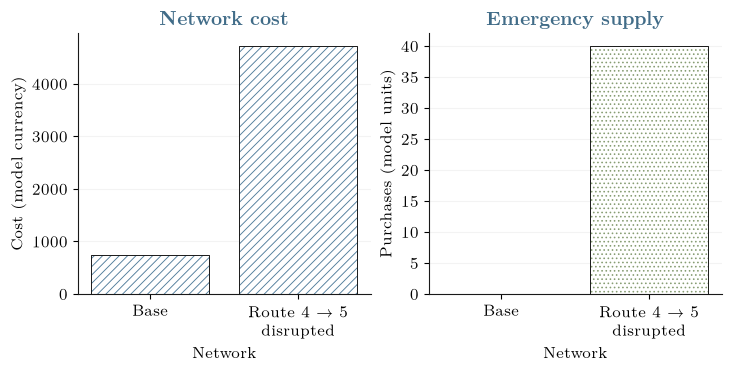

In [3]:
from gana.plotting import bar, row

scenarios = ["Base", "Route 4 → 5\ndisrupted"]
network_cost = bar(
    results["Cost"].tolist(),
    x=scenarios,
    title="Network cost",
    ylabel="Cost (model currency)",
)
emergency = bar(
    results["Emergency purchases"].tolist(),
    x=scenarios,
    title="Emergency supply",
    ylabel="Purchases (model units)",
)
disruption_plot = row(
    network_cost, emergency, fig_size=(7.2, 3.6), xlabel="Network", ylim=(0, None)
)
disruption_plot.show();